In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest, confint_proportions_2indep, proportion_confint, proportion_effectsize
)
from statsmodels.stats.power import NormalIndPower

ALPHA = 0.05
rng = np.random.default_rng(555)

# Chart colors, always in this order: blue, orange, aqua. Gray for reference lines.
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "figure.dpi": 110,
})

# A/B testing with binary outcome (0/1)

Scenario: a marketing campaign targets users chosen by a propensity-to-buy model. Outcome per user: `converted` = 1 if they bought, else 0.

The `TRUE_*` constants are the ground truth used to simulate the data. In real life you never see them. Here we use them to check whether each test told the truth.

## How to read any test in this notebook

| Number | Question it answers | Rule of thumb |
|---|---|---|
| **Standard error (SE)** | If we reran the same experiment, how much would this number wobble? | Smaller = more precise. Shrinks with √n, so 4× the users only halves it. |
| **z** | How many SEs is the observed difference away from 0? | \|z\| > 1.96 ⟺ p < 0.05 |
| **p-value** | If there were truly no difference (H₀), how often would luck alone give a gap this big or bigger? | p < α = 0.05 → **significant** |
| **95% CI** | Which true values are consistent with the data? | Excludes 0 → significant. Its **width** tells you how precise the estimate is. |

What a p-value is **not**:
- It is not the probability that H₀ is true.
- It is not the size of the effect. A tiny, useless lift with a huge n still gets a tiny p.
- p > 0.05 does not prove "no difference". It only means "not enough evidence". Always look at the CI to see what is still possible.

## How to study this notebook

Every test here is studied with the same three questions:

1. **Pick the right test.** What kind of outcome (0/1 here)? How many arms? Did they run at the same time? Is the old rate a sample or a fixed number?
2. **Use the right tool.** Do it by hand once to understand it, then use the library call (`statsmodels` / `scipy`).
3. **Read it the right way.** Significant or not? What do the SE, MoE, CI and p-value say? What is the catch?

## Vocabulary

| Term | Meaning | In this notebook |
|---|---|---|
| **Arm** | One of the groups in an experiment, each getting its own version. An A/B test has 2 arms; an A/B/C test has 3. The word comes from medical trials ("treatment arm"). | old-model arm, new-model arm |
| **Control** | The arm that gets the current version: the baseline to beat | old model |
| **Treatment** (or variant) | The arm that gets the new version | new model |
| **Per arm** | Per group. "10k per arm" in an A/B test = 20k customers in total | `N_PER_ARM_C1` |
| **Unit** | What gets randomly assigned to an arm. Here: one customer | `user_id` |
| **Randomization** | Each customer is put into an arm by chance, so the arms differ only in the version they get | Case 1 |
| **Conversion rate** | Buyers ÷ customers in an arm | `converted.mean()` |
| **pp** (percentage points) | Plain difference between two percentages: 5.0% → 5.8% = **+0.8pp** | |
| **Relative lift** | The difference as a % of the control rate: 0.8 / 5.0 = **+16%** | |
| **H₀ / H₁** | H₀ = "no difference between the arms". H₁ = "there is a difference". The test looks for evidence against H₀. | |
| **A/A test** | Both arms get the same version. Any "significant" result is a false alarm. Used to check the setup. | Problem 2 |

# Part A: Mock data

## Case 1: old model vs new model running at the same time

Users are randomly split 50/50 during the same period. Control = old model, treatment = new model.

In [3]:
N_PER_ARM_C1 = 10_000
TRUE_P_OLD_C1 = 0.050
TRUE_P_NEW_C1 = 0.058

n = 2 * N_PER_ARM_C1
case1 = pd.DataFrame({
    "user_id": np.arange(1, n + 1),
    "group": rng.permutation(np.repeat(["control", "treatment"], N_PER_ARM_C1)),
})
case1["model"] = case1["group"].map({"control": "old", "treatment": "new"})
case1["assigned_date"] = pd.Timestamp("2026-09-01") + pd.to_timedelta(rng.integers(0, 28, n), unit="D")
p = np.where(case1["group"] == "treatment", TRUE_P_NEW_C1, TRUE_P_OLD_C1)
case1["converted"] = rng.binomial(1, p)

case1.head()

,user_id,group,model,assigned_date,converted
0,1,control,old,2026-09-28,0
1,2,treatment,new,2026-09-24,0
2,3,treatment,new,2026-09-12,0
3,4,control,old,2026-09-27,0
4,5,treatment,new,2026-09-23,0


## Case 2.1: old model from historical records

The old model ran a campaign in March 2026 and we still have its user-level records. The new model runs now (September 2026). The two groups are **not** from the same period.

Hidden in the simulation: the baseline conversion rate also drifts between the periods (seasonality). The model lift and the seasonal shift add up in the observed difference.

In [4]:
N_HIST_C21 = 15_000
N_NEW_C21 = 10_000
TRUE_P_OLD_C21 = 0.050
TRUE_SEASONAL_SHIFT_C21 = 0.004  # baseline lift in September that has nothing to do with the model
TRUE_MODEL_LIFT_C21 = 0.004
TRUE_P_NEW_C21 = TRUE_P_OLD_C21 + TRUE_SEASONAL_SHIFT_C21 + TRUE_MODEL_LIFT_C21

hist = pd.DataFrame({
    "model": "old",
    "assigned_date": pd.Timestamp("2026-03-01") + pd.to_timedelta(rng.integers(0, 31, N_HIST_C21), unit="D"),
    "converted": rng.binomial(1, TRUE_P_OLD_C21, N_HIST_C21),
})
new = pd.DataFrame({
    "model": "new",
    "assigned_date": pd.Timestamp("2026-09-01") + pd.to_timedelta(rng.integers(0, 28, N_NEW_C21), unit="D"),
    "converted": rng.binomial(1, TRUE_P_NEW_C21, N_NEW_C21),
})
case2_1 = pd.concat([hist, new], ignore_index=True)
case2_1.insert(0, "user_id", np.arange(1, len(case2_1) + 1))

case2_1.head()

,user_id,model,assigned_date,converted
0,1,old,2026-03-29,0
1,2,old,2026-03-04,0
2,3,old,2026-03-03,0
3,4,old,2026-03-09,0
4,5,old,2026-03-07,0


## Case 2.2: old model has a known conversion rate

There is no user-level data for the old model, only a number the business reports: "the old model converts at 5%". We only collect data for the new model.

In [5]:
KNOWN_P_OLD_C22 = 0.050  # reported benchmark, treated as a fixed number
N_NEW_C22 = 10_000
TRUE_P_NEW_C22 = 0.056

case2_2 = pd.DataFrame({
    "user_id": np.arange(1, N_NEW_C22 + 1),
    "model": "new",
    "assigned_date": pd.Timestamp("2026-09-01") + pd.to_timedelta(rng.integers(0, 28, N_NEW_C22), unit="D"),
    "converted": rng.binomial(1, TRUE_P_NEW_C22, N_NEW_C22),
})

case2_2.head()

,user_id,model,assigned_date,converted
0,1,new,2026-09-18,0
1,2,new,2026-09-06,0
2,3,new,2026-09-12,0
3,4,new,2026-09-02,0
4,5,new,2026-09-04,0


## Quick look (always look at the data before testing it)

In [6]:
print("Case 1")
print(case1.groupby("model")["converted"].agg(["count", "sum", "mean"]), "\n")
print("Case 2.1")
print(case2_1.groupby("model")["converted"].agg(["count", "sum", "mean"]), "\n")
print("Case 2.2")
print(case2_2["converted"].agg(["count", "sum", "mean"]), f"\nknown old rate = {KNOWN_P_OLD_C22}")

Case 1
       count  sum    mean
model                    
new    10000  606  0.0606
old    10000  488  0.0488 

Case 2.1
       count  sum      mean
model                      
new    10000  542  0.054200
old    15000  751  0.050067 

Case 2.2
count    10000.0000
sum        563.0000
mean         0.0563
Name: converted, dtype: float64 
known old rate = 0.05


# Part B: Testing each case

## Case 1 test: two-proportion z-test

- H₀: p_new = p_old (the new model is no better or worse)
- H₁: p_new ≠ p_old (two-sided: we would also want to know if it is worse)

Two different SEs are used:
- **Pooled SE for the test.** The test asks "what if H₀ is true?", and under H₀ both groups share one rate, so we pool them.
- **Unpooled SE for the CI.** The CI does not assume H₀, so each group keeps its own rate.

In [7]:
summary = case1.groupby("model")["converted"].agg(["sum", "count"])
x_new, n_new = summary.loc["new"]
x_old, n_old = summary.loc["old"]
p_new, p_old = x_new / n_new, x_old / n_old
diff = p_new - p_old

# Test: pooled SE
p_pool = (x_new + x_old) / (n_new + n_old)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_new + 1 / n_old))
z = diff / se_pool
p_value = 2 * (1 - stats.norm.cdf(abs(z)))  # two-sided

# CI: unpooled SE
se_unpool = np.sqrt(p_new * (1 - p_new) / n_new + p_old * (1 - p_old) / n_old)
z_crit = stats.norm.ppf(1 - ALPHA / 2)  # 1.96 for alpha = 0.05
ci_low, ci_high = diff - z_crit * se_unpool, diff + z_crit * se_unpool

print(f"old={p_old:.4f}  new={p_new:.4f}  diff={diff:.4f}")
print(f"SE (pooled)={se_pool:.5f}  z={z:.3f}  p-value={p_value:.5f}")
print(f"SE (unpooled)={se_unpool:.5f}  95% CI for diff: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"truth: diff={TRUE_P_NEW_C1 - TRUE_P_OLD_C1:.4f}")

old=0.0488  new=0.0606  diff=0.0118
SE (pooled)=0.00322  z=3.669  p-value=0.00024
SE (unpooled)=0.00321  95% CI for diff: [0.0055, 0.0181]
truth: diff=0.0080


Library version, which should match the hand calculation:

In [8]:
z, p_value = proportions_ztest([x_new, x_old], [n_new, n_old])
ci_low, ci_high = confint_proportions_2indep(x_new, n_new, x_old, n_old)

print(f"z={z:.3f}  p-value={p_value:.5f}")
print(f"95% CI for diff: [{ci_low:.4f}, {ci_high:.4f}]")

z=3.669  p-value=0.00024
95% CI for diff: [0.0055, 0.0181]


The same steps wrapped in a function, so the rest of the notebook can reuse them:

In [9]:
def two_prop_test(x_new, n_new, x_old, n_old, alpha=ALPHA):
    """Two-proportion z-test (pooled SE) and Wald CI (unpooled SE) for p_new - p_old."""
    p_new, p_old = x_new / n_new, x_old / n_old
    diff = p_new - p_old
    p_pool = (x_new + x_old) / (n_new + n_old)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_new + 1 / n_old))
    z = diff / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    se_unpool = np.sqrt(p_new * (1 - p_new) / n_new + p_old * (1 - p_old) / n_old)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    return pd.Series({
        "p_new": p_new, "p_old": p_old, "diff": diff,
        "se_pool": se_pool, "z": z, "p_value": p_value,
        "ci_low": diff - z_crit * se_unpool, "ci_high": diff + z_crit * se_unpool,
        "significant": p_value < alpha,
    })


def counts(df):
    s = df.groupby("model")["converted"].agg(["sum", "count"])
    return s.loc["new", "sum"], s.loc["new", "count"], s.loc["old", "sum"], s.loc["old", "count"]


two_prop_test(*counts(case1))

p_new            0.0606
p_old            0.0488
diff             0.0118
se_pool        0.003216
z              3.669345
p_value        0.000243
ci_low         0.005499
ci_high        0.018101
significant        True
dtype: object

### Case 1 conclusion: ✅ significant

| | Value | What it tells us |
|---|---|---|
| Observed diff | **+1.18pp** (4.88% → 6.06%, +24% relative) | The raw gap |
| SE (pooled) | 0.32pp | Rerunning this experiment, the gap would typically wobble by about ±0.32pp |
| z | 3.67 | The gap is 3.7 wobbles away from 0. Hard to get by luck. |
| p-value | 0.00024 | If the models were truly equal, a gap this big happens in about 1 of 4,000 experiments |
| 95% CI | [+0.55pp, +1.81pp] | Excludes 0 → significant. The true lift is plausibly anywhere in this range. |

**Decision:** the new model converts better. Ship it.

**The catch:**
1. **The CI is wide.** The lift could be +0.55pp (+11%) or +1.81pp (+37%). If the new model costs money to run, check that the *low end* of the CI still pays for it. "Significant" ≠ "big enough to matter".
2. **The observed lift overestimates the truth.** Truth is +0.80pp, we saw +1.18pp. This test only had about 71% power (see Problem 1). With low power, the experiments that *do* come out significant tend to be the ones where luck pushed the gap up. This is called the **winner's curse**. Expect the lift to be smaller after launch.
3. The z-test relies on the normal approximation. That's fine here (about 500 conversions per arm). With fewer than about 10 conversions in an arm, use Fisher's exact test (`stats.fisher_exact`).

## Case 2.1 test: same two-proportion z-test, on non-concurrent groups

The data has the same shape as Case 1, so the same test runs. What changes is what the result **means**.

In [10]:
res_c21 = two_prop_test(*counts(case2_1))
print(res_c21, "\n")
print(f"truth: total gap={TRUE_P_NEW_C21 - TRUE_P_OLD_C21:.4f}"
      f"  = model {TRUE_MODEL_LIFT_C21:.4f} + season {TRUE_SEASONAL_SHIFT_C21:.4f}")

p_new            0.0542
p_old          0.050067
diff           0.004133
se_pool        0.002859
z              1.445701
p_value        0.148261
ci_low        -0.001512
ci_high        0.009779
significant       False
dtype: object 

truth: total gap=0.0080  = model 0.0040 + season 0.0040


### Case 2.1 conclusion: ❌ not significant (and confounded)

| | Value | What it tells us |
|---|---|---|
| Observed diff | **+0.41pp** (5.01% → 5.42%) | The raw gap, which mixes model and season |
| SE (pooled) | 0.29pp | *Smaller* than Case 1 (more users), so precision is not the problem |
| z | 1.45 | Only 1.45 wobbles from 0. Luck explains this easily. |
| p-value | 0.148 | If there were no difference, a gap this big would happen about 15% of the time |
| 95% CI | [−0.15pp, +0.98pp] | Includes 0 → not significant. It *also* includes +0.8pp (the truth). |

**Decision:** no evidence the new model is better. That is **not** the same as "the new model is no better". The CI says the true gap could be anywhere from slightly negative to almost +1pp.

**The catch:**
1. **Missed a real effect (false negative).** The true gap is +0.8pp, but this sample came out at only +0.41pp by bad luck. The test had about 78% power, so roughly 1 in 5 experiments like this misses. See Problem 1.
2. **Confounded, even if it had been significant.** The gap = model (+0.4pp) + season (+0.4pp). A significant result would *not* prove the model works. Half of it would be September being a better month. The test math is correct; the **design** is what breaks. See Problem 3.
3. Same data shape as Case 1, same code, different meaning. **Randomizing at the same time is what lets you read a difference as caused by the model.**

## Case 2.2 test: one-sample proportion test against a fixed number

Only the new model is a sample. The old rate is treated as an exact constant p₀ = 5%.

- H₀: p_new = p₀
- SE uses p₀ (the H₀ value): SE = √(p₀(1−p₀)/n). There is only **one** source of noise.
- `binomtest` is the exact version (no normal approximation), which is useful when n or the count of conversions is small.

In [11]:
x = case2_2["converted"].sum()
n = len(case2_2)
p0 = KNOWN_P_OLD_C22

# By hand
se = np.sqrt(p0 * (1 - p0) / n)
z = (x / n - p0) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"new={x/n:.4f}  vs known={p0}  SE={se:.5f}  z={z:.3f}  p-value={p_value:.4f}")

# Library versions
print("statsmodels z-test (z, p):", proportions_ztest(x, n, value=p0, prop_var=p0))
print("exact binomial p-value:", stats.binomtest(x, n, p0).pvalue)
ci_low, ci_high = proportion_confint(x, n, method="wilson")
print(f"95% CI for new rate: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"truth: new rate={TRUE_P_NEW_C22}")

new=0.0563  vs known=0.05  SE=0.00218  z=2.891  p-value=0.0038
statsmodels z-test (z, p): (np.float64(2.890638246769078), np.float64(0.003844603917020126))
exact binomial p-value: 0.004431883964145517
95% CI for new rate: [0.0520, 0.0610]
truth: new rate=0.056


### Case 2.2 conclusion: ✅ significant (if you trust the 5%)

| | Value | What it tells us |
|---|---|---|
| Observed rate | **5.63%** vs known 5.00% (+0.63pp) | |
| SE | 0.22pp | Smaller than Case 1's 0.32pp. Only one group is noisy, the 5% is treated as exact. |
| z | 2.89 | 2.9 wobbles above 5% |
| p-value | 0.0038 (exact binomial: 0.0044) | Both well below 0.05. With n this large the normal approximation and the exact test agree. |
| 95% CI for new rate | [5.20%, 6.10%] | Excludes 5% → significant |

**Decision:** the new model converts above 5%.

**The catch:**
1. **Everything rests on "5% is exact and still true today".** The SE only counts noise in the new sample. If the 5% was measured on a small sample, or measured long ago, this test is overconfident. Problem 4 shows how badly that can go.
2. **It is still a comparison across time**, like Case 2.1. The 5% came from some past period with past customers. Seasonality can hide inside it too.
3. Note the CI here is for the **new rate**, not for the difference, because the old rate has no uncertainty in this setup.

# How to read SE and MoE

## Standard error (SE)

**Meaning:** if we reran the same test on *different* customers, how much would this number typically change?

Your test saw 98 buyers out of 200 (49%). Another 200 customers would not give exactly 49%. They might give 46% or 52%. **The SE is the typical size of that change.**

**Formulas**

| SE of… | Formula | Used for |
|---|---|---|
| One arm's conversion rate | √( p(1−p) / n ) | Describing one arm |
| Difference between two arms (unpooled) | √( SE_old² + SE_new² ) = √( p₁(1−p₁)/n₁ + p₂(1−p₂)/n₂ ) | The CI |
| Difference between two arms (pooled, `se_pool`) | √( p̄(1−p̄)(1/n₁ + 1/n₂) ), where p̄ = all buyers ÷ all customers | The z-test and p-value |

- **p(1−p)** = how unpredictable *one* customer is. Largest at p = 50% (a coin toss). Small at 5% (almost nobody buys, so it's predictable).
- **÷ n** = averaging many customers cancels out their randomness.
- **√** = the cancelling is slow. 4× the customers only halves the SE.
- **Two arms:** SEs add like the sides of a right triangle, not as a plain sum, because one arm's luck can partly cancel the other's.
- **Pooled vs unpooled:** the z-test asks "what if both arms really have the same rate (H₀)?", so it uses one shared rate p̄. The CI assumes nothing, so each arm keeps its own rate. With large samples they're almost identical.

**How to read an SE**

| Ask | Rule |
|---|---|
| How much can I trust this number? | Same unit as the result. "+9.7pp with SE 5.35pp" is very rough. "+1.18pp with SE 0.32pp" is fairly solid. |
| Is it bigger than luck? | Divide: **z = result ÷ SE**. Around ±2 is the line between "could be luck" and "unlikely to be luck". |
| How do I make it smaller? | More customers (4× → half the SE). Rates near 50% are the noisiest. |
| Does a bigger lift change it? | No. The SE depends only on n and p(1−p), not on how big the difference is. |

## Margin of error (MoE)

**Meaning:** the furthest that luck *plausibly* pushes the result. It covers 95% of reruns.

**Formula:** MoE = 1.96 × SE (often rounded to **2 × SE**). The 1.96 comes from the bell curve: 95% of random wobble falls within 1.96 SEs. For 99% confidence, use 2.58 instead.

**How to read an MoE**

| Ask | Rule |
|---|---|
| How to say it | "result ± MoE", like a poll: "52% ± 3%". Here: "+9.7pp ± 10.5pp". |
| Is it significant? | If the MoE is **bigger** than the result, the result could be zero → **not significant**. (Same as "the CI includes 0".) |
| Link to the CI | MoE = half the CI width. CI = result ± MoE. |
| Is it good enough for a decision? | Compare the MoE to the decision. If you need to know whether the lift is +2pp or +5pp, a ±10pp MoE can't tell you. |

In [12]:
def se_rate(x, n):
    p = x / n
    return np.sqrt(p * (1 - p) / n)


z_crit = stats.norm.ppf(1 - ALPHA / 2)  # 1.96
rows = []
for label, x_new, n_new, x_old, n_old in [
    ("Small test (150 vs 200)", 88, 150, 98, 200),
    ("Case 1 (10k vs 10k)", *counts(case1)),
]:
    se_old, se_new = se_rate(x_old, n_old), se_rate(x_new, n_new)
    se_diff = np.sqrt(se_old ** 2 + se_new ** 2)   # NOT se_old + se_new
    diff = x_new / n_new - x_old / n_old
    rows.append({
        "test": label,
        "old rate %": x_old / n_old * 100, "SE old (pp)": se_old * 100,
        "new rate %": x_new / n_new * 100, "SE new (pp)": se_new * 100,
        "diff (pp)": diff * 100, "SE diff (pp)": se_diff * 100,
        "MoE diff (pp)": z_crit * se_diff * 100, "z = diff / SE": diff / se_diff,
    })
pd.DataFrame(rows).set_index("test").round(2).T

test,Small test (150 vs 200),Case 1 (10k vs 10k)
old rate %,49.00,4.88
SE old (pp),3.53,0.22
new rate %,58.67,6.06
SE new (pp),4.02,0.24
diff (pp),9.67,1.18
SE diff (pp),5.35,0.32
MoE diff (pp),10.49,0.63
z = diff / SE,1.81,3.67


**SE is not just a formula.** Rerun the old arm of the small test (200 customers, true rate 49%) 10,000 times. The spread of the results *is* the SE, and ±MoE covers about 95% of them.

std of 10,000 reruns = 3.50pp   formula SE = 3.53pp
reruns within ±SE  (±3.5pp): 71%   (about 68%)
reruns within ±MoE (±6.9pp): 95%   (about 95%)


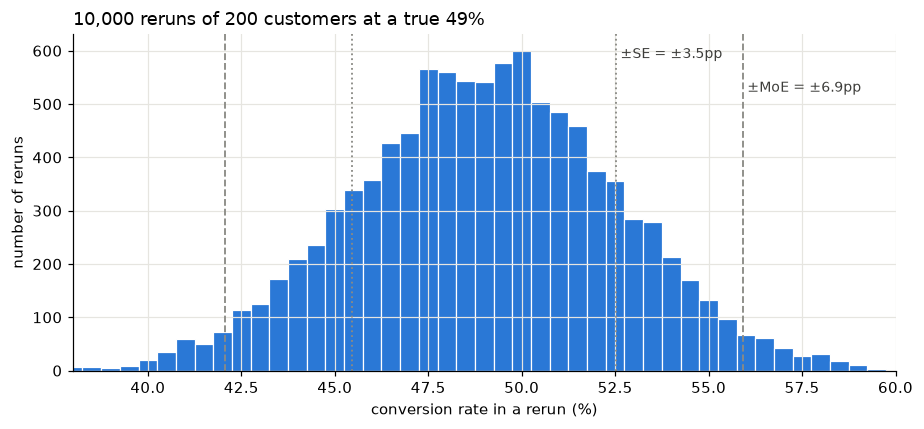

In [13]:
sim = np.random.default_rng(10)
p_true, n = 0.49, 200
reruns = sim.binomial(n, p_true, size=10_000) / n
se_formula = np.sqrt(p_true * (1 - p_true) / n)
moe_formula = z_crit * se_formula

print(f"std of 10,000 reruns = {reruns.std() * 100:.2f}pp   formula SE = {se_formula * 100:.2f}pp")
print(f"reruns within ±SE  (±{se_formula * 100:.1f}pp): {(np.abs(reruns - p_true) <= se_formula).mean():.0%}   (about 68%)")
print(f"reruns within ±MoE (±{moe_formula * 100:.1f}pp): {(np.abs(reruns - p_true) <= moe_formula).mean():.0%}   (about 95%)")

fig, ax = plt.subplots(figsize=(8.5, 4))
edges = (np.arange(n + 2) - 0.5) / n * 100   # one bin per possible buyer count
ax.hist(reruns * 100, bins=edges, color=C_BLUE, edgecolor="white", linewidth=0.8)
top = ax.get_ylim()[1]
for k, style, name in [(se_formula, ":", "SE"), (moe_formula, "--", "MoE")]:
    for sign in (-1, 1):
        ax.axvline((p_true + sign * k) * 100, color=C_GRAY, linestyle=style, linewidth=1.2)
    ax.text((p_true + k) * 100, top * (0.96 if name == "SE" else 0.86), f" ±{name} = ±{k * 100:.1f}pp",
            color="#3d3d3a", fontsize=9, va="top")
ax.set_xlim(38, 60)
ax.set_xlabel("conversion rate in a rerun (%)")
ax.set_ylabel("number of reruns")
ax.set_title("10,000 reruns of 200 customers at a true 49%", loc="left")
plt.tight_layout()
plt.show()

### Reading SE and MoE: small test vs Case 1

| | Small test (150 vs 200) | Case 1 (10k vs 10k) |
|---|---|---|
| Difference | +9.7pp | +1.18pp |
| SE of difference | 5.35pp | 0.32pp |
| MoE | ±10.5pp | ±0.63pp |
| Result vs MoE | 9.7 < 10.5 → could be 0 → **not significant** | 1.18 > 0.63 → can't be 0 → **significant** |
| Say it as | "+9.7pp, give or take 10.5pp" | "+1.2pp, give or take 0.6pp" |

The small test has the bigger lift but a far bigger SE: fewer customers *and* a noisier rate (49% vs 5%). The SE is about 17× larger, so the result is far less trustworthy.

**Common mistakes**

| ❌ Wrong | ✅ Right |
|---|---|
| SE is the same as standard deviation (SD) | SD = how different **customers** are from each other: √(p(1−p)) ≈ 50pp at 49%. It does not shrink with more customers. SE = how much the **average** moves between reruns. It shrinks with √n. |
| SE of the difference = SE_old + SE_new | √(SE_old² + SE_new²). 3.5 + 4.0 = 7.5 is wrong; the right answer is 5.35. |
| MoE always means ±2 SE | Only at 95% confidence. At 99% it is 2.58 × SE. |
| A small SE means a big effect | SE is about precision, not size. A tiny lift can have a tiny SE. |

# How to read a confidence interval (CI)

A CI is the **range of believable values for the true improvement**. The test only saw one sample of customers. A different sample would give a slightly different number. The CI says: "allowing for that luck, the real improvement is probably somewhere in here."

**Read 3 things, in this order:**

1. **Does it include 0?** 0 means "no difference".
   - 0 outside → every believable value is an improvement (or every one is a loss) → **significant**
   - 0 inside → "no difference" is still believable → **not significant**
   - This always agrees with the p-value: a 95% CI excludes 0 exactly when p < 0.05.
2. **The two ends = worst case and best case.** Compare the **low end** with the break-even lift. If even the worst case pays for the switch, ship with confidence.
3. **The width = how precise the test is.** Narrow = we know the lift well. Wide = not enough data.

**Names and formula** (textbook Wald version):

| Name | Formula |
|---|---|
| Standard error (SE) | √( p_new(1−p_new)/n_new + p_old(1−p_old)/n_old ) |
| **Margin of error (MoE)**, the "±" part | 1.96 × SE (1.96 because 95% of a normal curve lies within ±1.96 SE) |
| **CI width** | 2 × MoE = high end − low end |
| **CI** | observed diff ± MoE |

The width depends only on **sample size** and **noise** (p(1−p), largest near 50%). The observed difference does not affect it. **4× the customers → half the width.**

Below, three tests side by side, including a small test: old model 98 buyers out of 200 vs new model 88 out of 150.

In [14]:
# By hand, for the small test
p_new, n_new = 88 / 150, 150
p_old, n_old = 98 / 200, 200

se = np.sqrt(p_new * (1 - p_new) / n_new + p_old * (1 - p_old) / n_old)
moe = stats.norm.ppf(1 - ALPHA / 2) * se
diff = p_new - p_old
print(f"diff = {diff * 100:+.1f}pp   SE = {se * 100:.2f}pp   MoE = ±{moe * 100:.1f}pp   width = {2 * moe * 100:.1f}pp")
print(f"95% CI = [{(diff - moe) * 100:+.1f}pp, {(diff + moe) * 100:+.1f}pp]")

diff = +9.7pp   SE = 5.35pp   MoE = ±10.5pp   width = 21.0pp
95% CI = [-0.8pp, +20.2pp]


In [15]:
ci_examples = pd.DataFrame({
    "Case 1 (10k vs 10k)": two_prop_test(*counts(case1)),
    "Case 2.1 (10k vs 15k)": two_prop_test(*counts(case2_1)),
    "Small test (150 vs 200)": two_prop_test(88, 150, 98, 200),
}).T
ci_pp = ci_examples[["diff", "ci_low", "ci_high"]].astype(float) * 100   # in percentage points
ci_pp["margin_of_error"] = (ci_pp["ci_high"] - ci_pp["ci_low"]) / 2
ci_pp["width"] = ci_pp["ci_high"] - ci_pp["ci_low"]
ci_pp["significant"] = ci_examples["significant"]
ci_pp.round(2)

,diff,ci_low,ci_high,margin_of_error,width,significant
Case 1 (10k vs 10k),1.18,0.55,1.81,0.63,1.26,True
Case 2.1 (10k vs 15k),0.41,-0.15,0.98,0.56,1.13,False
Small test (150 vs 200),9.67,-0.83,20.16,10.49,20.99,False


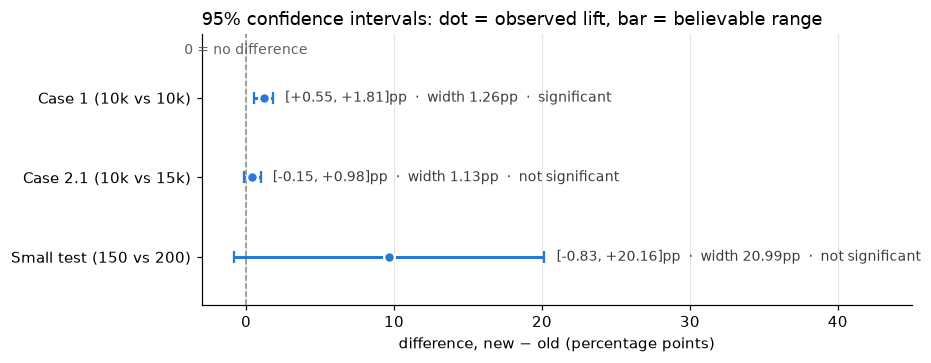

In [16]:
labels = ci_pp.index[::-1]   # first example on top
y = np.arange(len(labels))
rows = ci_pp.loc[labels]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.axvline(0, color=C_GRAY, linestyle="--", linewidth=1)
ax.text(0, len(labels) - 0.45, "0 = no difference", color="#5f5e5a", fontsize=9, ha="center")
ax.errorbar(rows["diff"], y,
            xerr=[rows["diff"] - rows["ci_low"], rows["ci_high"] - rows["diff"]],
            fmt="o", color=C_BLUE, ecolor=C_BLUE, elinewidth=2, capsize=4, markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
for yi, (_, r) in zip(y, rows.iterrows()):
    verdict = "significant" if r["significant"] else "not significant"
    ax.annotate(f"[{r.ci_low:+.2f}, {r.ci_high:+.2f}]pp  ·  width {r.width:.2f}pp  ·  {verdict}",
                (r.ci_high, yi), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#3d3d3a")
ax.set_yticks(y, labels)
ax.set_xlabel("difference, new − old (percentage points)")
ax.set_xlim(-3, 45)
ax.set_ylim(-0.6, len(labels) - 0.2)
ax.grid(axis="y", visible=False)
ax.set_title("95% confidence intervals: dot = observed lift, bar = believable range", loc="left")
plt.tight_layout()
plt.show()

### Reading the three CIs

| Test | CI | 0 inside? | Worst / best case | Width | Reading |
|---|---|---|---|---|---|
| Case 1 | [+0.55, +1.81]pp | No → ✅ significant | +0.55 / +1.81 | 1.3pp | The new model is better, and we know by roughly how much. Ship if +0.55pp pays for it. |
| Case 2.1 | [−0.15, +0.98]pp | Yes → ❌ | −0.15 / +0.98 | 1.1pp | Precise, but can't rule out zero. (And confounded by season.) |
| Small test | [−0.8, +20.2]pp | Yes → ❌ | −0.8 / +20.2 | 21pp | Could be slightly worse or massively better. Far too vague to decide. Needs more data. |

Notice that the small test has the **biggest observed lift** (+9.7pp) but the **least useful** result. The size of the dot means nothing without the width of the bar.

**Common mistakes**

| ❌ Wrong reading | ✅ Right reading |
|---|---|
| "Not significant, so there's no effect." | 0 is *one* believable value, but so is the high end. We don't know. |
| "The lift is +9.7pp." | +9.7pp is the middle of the range. The truth could be anywhere in it. |
| "Every value in the range is equally likely." | Values near the middle are more believable than values at the edges. |
| "Significant, so it's a big improvement." | Check the low end. Significant can still mean "only +0.1pp". |

**What does "95%" mean?** If you repeated the experiment 100 times and computed a CI each time, about 95 of those ranges would contain the true lift. About 5 would miss it through bad luck. So 95% is how often the *method* works, not a guarantee for any single test.

**Note on methods:** `two_prop_test` uses the textbook ± formula (Wald). `confint_proportions_2indep` uses the more refined Newcombe method by default, so its CI for the small test is slightly different ([−0.9, +19.9]pp) and not perfectly symmetric. With large samples they agree.

# Part C: Problems

## Problem 1: Power and sample size (why Case 2.1 missed a real lift)

A test can make two kinds of mistake:

| | H₀ true (no real lift) | H₁ true (real lift) |
|---|---|---|
| **Test says significant** | False positive. Rate = **α** (we set 5%) | Correct. Rate = **power** |
| **Test says not significant** | Correct | False negative. Rate = **β** = 1 − power |

**Power** = the chance the test detects a lift that really exists. The industry default is 80%.

Before running a test, choose four knobs and solve for the fifth:
1. **α**, usually 0.05
2. **power**, usually 0.80
3. **baseline rate** p_old (from history)
4. **MDE** (minimum detectable effect): the smallest lift worth detecting, a business decision
5. → **n per arm**

Formula (equal arms):

n per arm ≈ (z₁₋α/₂ + z_power)² × [p_old(1−p_old) + p_new(1−p_new)] / (p_new − p_old)²

Note the MDE is squared in the denominator: **half the lift needs 4× the users.**

In [17]:
def n_per_arm(p_old, p_new, alpha=ALPHA, power=0.80):
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    var = p_old * (1 - p_old) + p_new * (1 - p_new)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p_new - p_old) ** 2))


def power_two_prop(p_old, p_new, n_new, n_old, alpha=ALPHA):
    """Approximate power of the two-sided two-proportion z-test."""
    z_a = stats.norm.ppf(1 - alpha / 2)
    se = np.sqrt(p_old * (1 - p_old) / n_old + p_new * (1 - p_new) / n_new)
    return stats.norm.cdf(abs(p_new - p_old) / se - z_a)


scenarios = pd.DataFrame([
    {"scenario": "Case 1: 5.0% -> 5.8%, 10k vs 10k", "p_old": 0.050, "p_new": 0.058, "n_new": 10_000, "n_old": 10_000},
    {"scenario": "Case 2.1: 5.0% -> 5.8%, 10k vs 15k", "p_old": 0.050, "p_new": 0.058, "n_new": 10_000, "n_old": 15_000},
    {"scenario": "Model-only lift: 5.4% -> 5.8%, 10k vs 10k", "p_old": 0.054, "p_new": 0.058, "n_new": 10_000, "n_old": 10_000},
])
scenarios["power_at_this_n"] = scenarios.apply(
    lambda r: power_two_prop(r.p_old, r.p_new, r.n_new, r.n_old), axis=1)
scenarios["n_per_arm_for_80%"] = scenarios.apply(lambda r: n_per_arm(r.p_old, r.p_new), axis=1)
scenarios.round(3)

,scenario,p_old,p_new,n_new,n_old,power_at_this_n,n_per_arm_for_80%
0,"Case 1: 5.0% -> 5.8%, 10k vs 10k",0.050,0.058,10000,10000,0.707,12526
1,"Case 2.1: 5.0% -> 5.8%, 10k vs 15k",0.050,0.058,10000,15000,0.777,12526
2,"Model-only lift: 5.4% -> 5.8%, 10k vs 10k",0.054,0.058,10000,10000,0.233,51862


Cross-check with `statsmodels`. It uses Cohen's h (an arcsine-transformed effect size), so the n is close to the formula but not identical:

In [18]:
h = proportion_effectsize(0.058, 0.050)
n_sm = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=0.80, ratio=1)
print(f"Cohen's h={h:.4f}  ->  n per arm={np.ceil(n_sm):.0f}  (formula: {n_per_arm(0.050, 0.058)})")

Cohen's h=0.0354  ->  n per arm=12514  (formula: 12526)


### Effect size in plain English (for marketing, sales and finance)

**The question it answers:** *how hard is it to tell whether the new model really works?*

Think of the improvement as a **whisper**, and the normal ups and downs in who buys as **background noise**.
- A +1pp lift on a **5%** conversion rate is a whisper in a quiet library. Easy to hear.
- The same +1pp lift on a **50%** conversion rate is a whisper at a party. When about half of customers buy, results swing much more from one group to the next, so the same improvement is harder to hear.

**Effect size** is a score for "how loud the whisper is compared with the noise". `proportion_effectsize(new_rate, old_rate)` calculates that score from two conversion rates.

| Effect size | What it means for the business |
|---|---|
| Bigger | Easy to spot → fewer customers, shorter test, cheaper |
| Smaller | Hard to spot → more customers, longer test, more expensive |

Nobody outside the data team needs to see the score. Its only job is to turn into the numbers stakeholders care about: **how many customers, and how many days, the test needs.**

In [19]:
# Same +1pp lift, different baselines: the quiet library vs the party
for old, new in [(0.05, 0.06), (0.50, 0.51)]:
    h = proportion_effectsize(new, old)
    n_arm = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=0.80, ratio=1)
    print(f"{old:.0%} -> {new:.0%}: effect size={h:.3f}  customers per group={np.ceil(n_arm):,.0f}")

5% -> 6%: effect size=0.044  customers per group=8,143
50% -> 51%: effect size=0.020  customers per group=39,240


**Turning effect size into a test plan.** Suppose the campaign reaches 2,000 customers a day, split 50/50 between old and new model. For each improvement we might want to prove, how long must the test run?

In [20]:
CUSTOMERS_PER_DAY = 2_000  # customers the campaign reaches per day, split 50/50
BASELINE = 0.05            # current conversion rate (old model)

rows = []
for target in [0.052, 0.055, 0.058, 0.060, 0.065]:
    h = proportion_effectsize(target, BASELINE)
    n_arm = int(np.ceil(NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=0.80, ratio=1)))
    rows.append({
        "we want to detect": f"{BASELINE:.1%} -> {target:.1%}",
        "relative lift": f"+{target / BASELINE - 1:.0%}",
        "effect size": round(h, 4),
        "customers per group": f"{n_arm:,}",
        "total customers": f"{2 * n_arm:,}",
        "days to run": int(np.ceil(2 * n_arm / CUSTOMERS_PER_DAY)),
    })
pd.DataFrame(rows)

,we want to detect,relative lift,effect size,customers per group,total customers,days to run
0,5.0% -> 5.2%,+4%,0.0091,"189,921","379,842",190
1,5.0% -> 5.5%,+10%,0.0224,"31,218","62,436",32
2,5.0% -> 5.8%,+16%,0.0354,"12,514","25,028",13
3,5.0% -> 6.0%,+20%,0.0439,"8,143","16,286",9
4,5.0% -> 6.5%,+30%,0.0646,"3,766","7,532",4


**How to say it to stakeholders** (numbers from the table above):

- *"If the new model really lifts conversion from 5.0% to 5.8%, we need about 25,000 customers, roughly 13 days, to have an 8-in-10 chance of seeing it."*
- *"Small improvements are expensive to prove. To catch a lift half that size, the test runs about 4 times longer."*
- *"If the test ends with no clear winner, that doesn't mean the model doesn't work. The improvement may be smaller than this test could see."*
- *"Before we start, tell us the smallest improvement that would be worth the cost of switching. That decides how long we test."*

**Jargon → plain English**

| Data team says | Say this instead |
|---|---|
| Effect size | How easy the improvement is to spot |
| MDE (minimum detectable effect) | The smallest improvement worth paying for |
| Power = 80% | An 8-in-10 chance we spot a real improvement |
| α = 0.05 | A 1-in-20 chance of a false alarm |
| Significant | Very unlikely to be just luck |
| 95% CI | The likely range of the true improvement |
| Not significant | We couldn't tell. Not the same as "it doesn't work" |

**Check by simulation:** rerun Case 1 5,000 times with the true rates and count how often the test comes out significant. That share *is* the power.

In [21]:
sim_rng = np.random.default_rng(1)
N_SIMS = 5_000

def sim_share_significant(p_old, p_new, n_new, n_old, n_sims=N_SIMS, rng=sim_rng):
    x_new = rng.binomial(n_new, p_new, n_sims)
    x_old = rng.binomial(n_old, p_old, n_sims)
    p_pool = (x_new + x_old) / (n_new + n_old)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_new + 1 / n_old))
    z = (x_new / n_new - x_old / n_old) / se
    p_values = 2 * (1 - stats.norm.cdf(np.abs(z)))
    return (p_values < ALPHA).mean()

print(f"simulated power, Case 1 setup: {sim_share_significant(0.050, 0.058, 10_000, 10_000):.3f}"
      f"  (formula: {power_two_prop(0.050, 0.058, 10_000, 10_000):.3f})")

simulated power, Case 1 setup: 0.709  (formula: 0.707)


**Power curve:** how power grows with n for three different true lifts (baseline 5%).

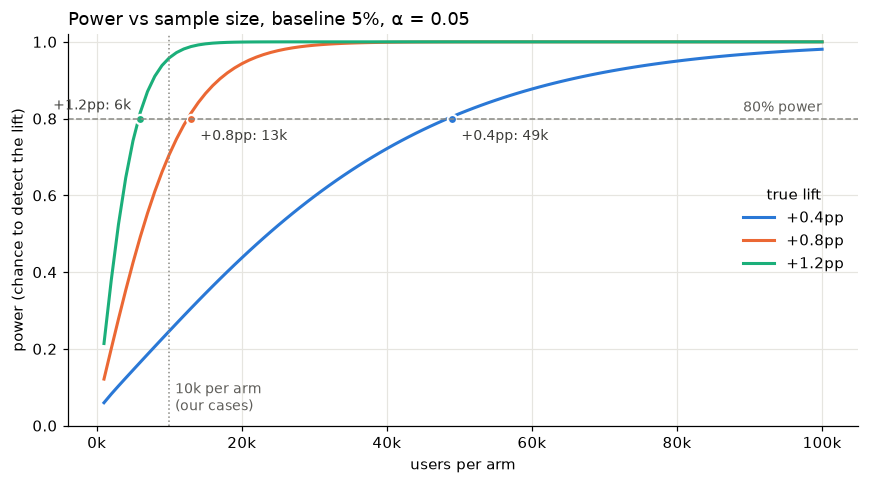

In [22]:
n_grid = np.arange(1_000, 100_001, 1_000)
fig, ax = plt.subplots(figsize=(8, 4.5))
# label offsets keep the three "n needed" labels from colliding
for lift, color, offset, ha in [(0.004, C_BLUE, (6, -14), "left"), (0.008, C_ORANGE, (6, -14), "left"),
                                (0.012, C_AQUA, (-6, 6), "right")]:
    power = power_two_prop(0.05, 0.05 + lift, n_grid, n_grid)
    ax.plot(n_grid, power, color=color, label=f"+{lift * 100:.1f}pp")
    n_80 = n_grid[np.argmax(power >= 0.80)]
    ax.plot(n_80, 0.80, "o", color=color, markersize=6, markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(f"+{lift * 100:.1f}pp: {n_80 / 1000:.0f}k", (n_80, 0.80), xytext=offset, ha=ha,
                textcoords="offset points", color="#3d3d3a", fontsize=9)
ax.axhline(0.80, color=C_GRAY, linestyle="--", linewidth=1)
ax.axvline(10_000, color=C_GRAY, linestyle=":", linewidth=1)
ax.text(10_800, 0.04, "10k per arm\n(our cases)", color="#5f5e5a", fontsize=9)
ax.text(n_grid[-1], 0.81, "80% power", color="#5f5e5a", fontsize=9, ha="right", va="bottom")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_xlabel("users per arm")
ax.set_ylabel("power (chance to detect the lift)")
ax.set_ylim(0, 1.02)
ax.set_title("Power vs sample size, baseline 5%, α = 0.05", loc="left")
ax.legend(title="true lift", frameon=False, loc="center right")
plt.tight_layout()
plt.show()

### Problem 1 conclusion

| Setup | Power | n per arm for 80% |
|---|---|---|
| Case 1: +0.8pp, 10k vs 10k | **71%** | 12,526 |
| Case 2.1: +0.8pp total gap, 10k vs 15k | 78% | |
| Model-only lift +0.4pp, 10k vs 10k | **23%** | **51,862** |

The simulation (70.9%) matches the formula (70.7%). Power really is "the share of experiments that catch the lift".

**What this teaches:**
1. **Case 1 was slightly underpowered.** About 29% of the time, a real +0.8pp lift would have come out "not significant". We got the significant result, partly helped by a lucky draw (the winner's curse from Case 1).
2. **Case 2.1 missed by bad luck, but the real problem is worse.** Even with a clean design, the model's own +0.4pp lift needs about 52k users per arm. With 10k you have only a 23% chance to catch it.
3. **Halving the lift needs about 4× the users.** In the chart, +0.8pp needs about 13k per arm and +0.4pp needs about 49k. That's because the MDE is squared in the formula.
4. **Do this before the experiment, not after.** Pick the MDE from the business ("what lift is worth shipping?"), compute n, then run until you reach n.

**The catch:** power analysis needs a guess of the baseline rate and the effect size. Use the MDE you *care about*, not the effect you *hope for*. An optimistic guess gives a sample that's too small.

## Problem 2: What does the p-value actually promise?

Simulate 10,000 experiments twice:
- **A/A tests:** both arms 5.0% (H₀ is true). Any "significant" result is a false positive.
- **A/B tests:** 5.0% vs 5.8% (H₁ is true, the Case 1 truth).

Then look at the distribution of p-values.

A/A: share with p < 0.05 = 0.051   (false positive rate, should be ~0.05)
A/B: share with p < 0.05 = 0.702   (power, should be ~0.71)


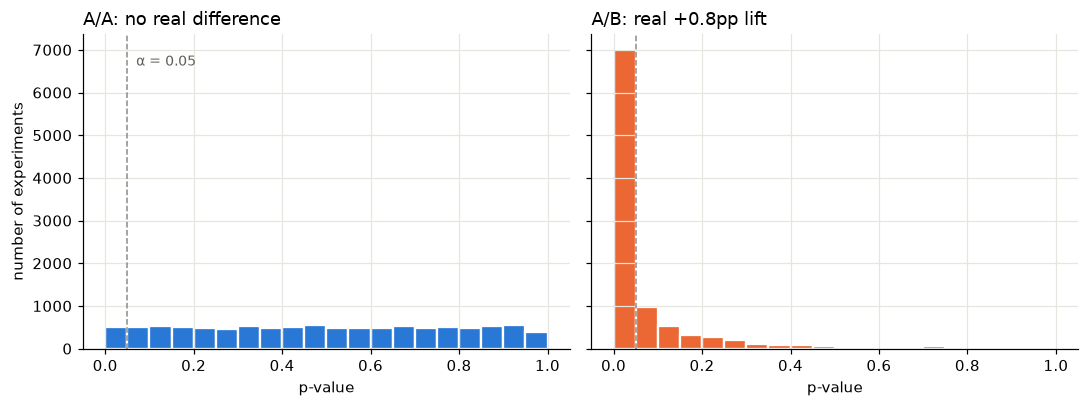

In [23]:
p2_rng = np.random.default_rng(2)
N_SIMS_P2 = 10_000
n_arm = 10_000

def sim_p_values(p_old, p_new, n_arm, n_sims, rng):
    x_new = rng.binomial(n_arm, p_new, n_sims)
    x_old = rng.binomial(n_arm, p_old, n_sims)
    p_pool = (x_new + x_old) / (2 * n_arm)
    se = np.sqrt(p_pool * (1 - p_pool) * (2 / n_arm))
    z = (x_new - x_old) / n_arm / se
    return 2 * (1 - stats.norm.cdf(np.abs(z)))

p_aa = sim_p_values(0.050, 0.050, n_arm, N_SIMS_P2, p2_rng)
p_ab = sim_p_values(0.050, 0.058, n_arm, N_SIMS_P2, p2_rng)
print(f"A/A: share with p < 0.05 = {(p_aa < ALPHA).mean():.3f}   (false positive rate, should be ~0.05)")
print(f"A/B: share with p < 0.05 = {(p_ab < ALPHA).mean():.3f}   (power, should be ~0.71)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, pv, color, title in [
    (axes[0], p_aa, C_BLUE, "A/A: no real difference"),
    (axes[1], p_ab, C_ORANGE, "A/B: real +0.8pp lift"),
]:
    ax.hist(pv, bins=bins, color=color, edgecolor="white", linewidth=1.5)
    ax.axvline(ALPHA, color=C_GRAY, linestyle="--", linewidth=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("p-value")
axes[0].set_ylabel("number of experiments")
axes[0].text(0.07, axes[0].get_ylim()[1] * 0.9, "α = 0.05", color="#5f5e5a", fontsize=9)
plt.tight_layout()
plt.show()

### Problem 2 conclusion

- **A/A (no real difference):** 5.1% of experiments came out "significant". That matches α = 5%. The p-values are spread **evenly between 0 and 1** (flat histogram): with no real effect, every p-value is equally likely.
- **A/B (real +0.8pp):** 70.2% came out significant. That's the power from Problem 1. The p-values pile up near 0.

**What a p-value promises:** if you only ever ship when p < 0.05, then among experiments where nothing is really different, you will wrongly ship 5% of the time. That's all. It does **not** say "95% chance the new model is better".

**The catch:**
1. **Multiple testing.** Check 20 metrics (or 20 segments) on an A/A test and you expect about 1 "significant" result by pure chance. Fixes: choose **one primary metric** in advance, or correct α (Bonferroni: α/number of tests; or Benjamini-Hochberg).
2. p = 0.049 and p = 0.051 are practically the same evidence. Don't treat 0.05 as magic. Report the CI.

## Problem 3: Fixing Case 2.1's seasonality trap with difference-in-differences (DiD)

The naive Case 2.1 comparison measures **model + season** together. To remove the season, we need a group that the model change did **not** touch, measured in both periods. Here: the general customer base that no campaign targeted (a **baseline group**).

|  | March | September | change |
|---|---|---|---|
| Targeted users | old model | new model | **model + season** |
| Baseline users | no campaign | no campaign | **season only** |

DiD = (change in targeted) − (change in baseline) = model effect.

Key assumption, **parallel trends**: without the new model, both groups would have moved by the same amount.

We simulate the baseline data below (in real life it comes from your data warehouse).

In [24]:
did_rng = np.random.default_rng(3)
N_BASE = 20_000
TRUE_P_BASE_MAR = 0.030
TRUE_P_BASE_SEP = TRUE_P_BASE_MAR + TRUE_SEASONAL_SHIFT_C21  # parallel trends holds in this simulation

base_mar = did_rng.binomial(1, TRUE_P_BASE_MAR, N_BASE)
base_sep = did_rng.binomial(1, TRUE_P_BASE_SEP, N_BASE)
old_mar = case2_1.loc[case2_1["model"] == "old", "converted"].to_numpy()
new_sep = case2_1.loc[case2_1["model"] == "new", "converted"].to_numpy()

groups = {"new_sep": new_sep, "old_mar": old_mar, "base_sep": base_sep, "base_mar": base_mar}
rate = {k: v.mean() for k, v in groups.items()}
se = {k: np.sqrt(v.mean() * (1 - v.mean()) / len(v)) for k, v in groups.items()}

naive = rate["new_sep"] - rate["old_mar"]
season = rate["base_sep"] - rate["base_mar"]
did = naive - season
# The four groups are independent, so their variances add
se_did = np.sqrt(sum(s ** 2 for s in se.values()))
se_naive = np.sqrt(se["new_sep"] ** 2 + se["old_mar"] ** 2)
z_did = did / se_did
p_did = 2 * (1 - stats.norm.cdf(abs(z_did)))
z_crit = stats.norm.ppf(1 - ALPHA / 2)

print(pd.Series(rate).round(4), "\n")
print(f"naive diff (model + season) = {naive:.4f}   SE={se_naive:.5f}")
print(f"season estimate             = {season:.4f}")
print(f"DiD (model only)            = {did:.4f}   SE={se_did:.5f}  z={z_did:.3f}  p-value={p_did:.4f}")
print(f"95% CI for model effect: [{did - z_crit * se_did:.4f}, {did + z_crit * se_did:.4f}]")
print(f"truth: model={TRUE_MODEL_LIFT_C21:.4f}, season={TRUE_SEASONAL_SHIFT_C21:.4f}")

new_sep     0.0542
old_mar     0.0501
base_sep    0.0336
base_mar    0.0306
dtype: float64 

naive diff (model + season) = 0.0041   SE=0.00288
season estimate             = 0.0030
DiD (model only)            = 0.0011   SE=0.00338  z=0.336  p-value=0.7372
95% CI for model effect: [-0.0055, 0.0078]
truth: model=0.0040, season=0.0040


### Problem 3 conclusion: ❌ not significant, but now asking the right question

| | Estimate | SE | Truth |
|---|---|---|---|
| Naive diff (model + season) | +0.41pp | 0.29pp | +0.80pp |
| Season (from baseline group) | +0.30pp | | +0.40pp |
| **DiD: model only** | **+0.11pp** | **0.34pp** | +0.40pp |

DiD z = 0.34, p = 0.74, 95% CI [−0.55pp, +0.78pp]. It includes 0 and also includes the true +0.4pp.

**What this teaches:**
1. DiD **removes the bias** (season) so the estimate now targets the model effect. Before, a significant result would have been misleading. Now, if it were significant, you could believe it.
2. **But it adds noise.** The SE went from 0.29pp to 0.34pp, because four groups each bring their own wobble (variances add). Removing bias costs precision.
3. Combined with Problem 1 (+0.4pp needs about 52k per arm), this data was never going to detect the model effect.

**The catch:**
1. **Parallel trends is an assumption you can't test with only two periods.** If targeted users react to September differently from baseline users, DiD is biased. In practice, check several *earlier* periods: did both groups move together before the change?
2. **The real fix is design, not math:** run old and new at the same time with random assignment (Case 1). If you can't, keep a small random **holdout** on the old model.

## Problem 4: How much should we trust a "known" 5%?

Case 2.2 treats 5% as exact. Two ways that can go wrong:

**4a. The 5% was itself measured on a sample.** Then it has its own SE, and the right test is the two-sample test. Below, the same new-model data is compared against "5%" measured on different numbers of users.

In [25]:
x_new = case2_2["converted"].sum()
n_new = len(case2_2)
rows = []
for n_old in [1_000, 2_000, 10_000, 100_000, 1_000_000]:
    x_old = round(KNOWN_P_OLD_C22 * n_old)
    r = two_prop_test(x_new, n_new, x_old, n_old)
    rows.append({"benchmark measured on": f"{n_old:,} users", "SE (pooled)": r.se_pool,
                 "p_value": r.p_value, "ci_low": r.ci_low, "ci_high": r.ci_high, "significant": r.significant})

# One-sample test = benchmark measured on infinitely many users
se_1s = np.sqrt(KNOWN_P_OLD_C22 * (1 - KNOWN_P_OLD_C22) / n_new)
z_1s = (x_new / n_new - KNOWN_P_OLD_C22) / se_1s
rows.append({"benchmark measured on": "treated as exact (one-sample)", "SE (pooled)": se_1s,
             "p_value": 2 * (1 - stats.norm.cdf(abs(z_1s))), "ci_low": np.nan, "ci_high": np.nan,
             "significant": abs(z_1s) > stats.norm.ppf(1 - ALPHA / 2)})
pd.DataFrame(rows).round(5)

,benchmark measured on,SE (pooled),p_value,ci_low,ci_high,significant
0,"1,000 users",0.00761,0.40764,-0.00794,0.02054,False
1,"2,000 users",0.00560,0.26027,-0.00427,0.01687,False
2,"10,000 users",0.00317,0.04706,0.00008,0.01252,True
3,"100,000 users",0.00230,0.00612,0.00158,0.01102,True
4,"1,000,000 users",0.00219,0.00405,0.00176,0.01084,True
5,treated as exact (one-sample),0.00218,0.00384,NaN,NaN,True


**4b. The 5% is stale.** Suppose the old model actually converts at 5.6% today (customers changed), and the new model is **no better** (also 5.6%). We still compare against the old 5%. How often do we wrongly declare a win?

In [26]:
p4_rng = np.random.default_rng(4)
n_sims = 5_000
TRUE_P_OLD_TODAY = 0.056
TRUE_P_NEW_SAME = 0.056  # no real lift

x = p4_rng.binomial(N_NEW_C22, TRUE_P_NEW_SAME, n_sims)
for label, benchmark in [("stale benchmark 5.0%", 0.050), ("up-to-date benchmark 5.6%", TRUE_P_OLD_TODAY)]:
    se_b = np.sqrt(benchmark * (1 - benchmark) / N_NEW_C22)
    z = (x / N_NEW_C22 - benchmark) / se_b
    share = (2 * (1 - stats.norm.cdf(np.abs(z))) < ALPHA).mean()
    print(f"{label:<26}: declared 'significant' in {share:.1%} of experiments")

stale benchmark 5.0%      : declared 'significant' in 77.0% of experiments
up-to-date benchmark 5.6% : declared 'significant' in 5.2% of experiments


### Problem 4 conclusion

**4a: how big was the benchmark's sample?** Same new-model data (5.63%), same "5%":

| 5% measured on | p-value | Significant? |
|---|---|---|
| 1,000 users | 0.41 | ❌ |
| 2,000 users | 0.26 | ❌ |
| 10,000 users | 0.047 | ✅ (barely) |
| 100,000 users | 0.006 | ✅ |
| treated as exact | 0.004 | ✅ |

The one-sample test is the limit of the two-sample test as the benchmark's sample size → ∞. The conclusion flips depending on how solid "5%" really is. Always ask: *5% measured on how many users, and when?*

**4b: stale benchmark.** The new model is **no better** than the old one today (both 5.6%):
- vs stale 5.0% → declared a "win" in **77%** of experiments
- vs up-to-date 5.6% → 5.2% (just α, as it should be)

**The catch:** the test can't know the benchmark is wrong. A stale benchmark turns α = 5% into a false-win rate of 77%. If you only have a benchmark, treat the result as weak evidence and push for a concurrent test or holdout.

## Problem 5: Sanity checks every real A/B test needs

### 5a. Sample Ratio Mismatch (SRM)

If you planned a 50/50 split, the arm sizes should be close to 50/50. A big mismatch means something broke in assignment or logging (e.g. the new model crashes for some users and they never get logged). Then **the groups are no longer comparable, and no test result can be trusted.**

Test: chi-square goodness-of-fit of observed counts vs expected counts. Use a strict α (often 0.001), because SRM is a "stop everything" alarm.

In [27]:
def srm_check(n_a, n_b, expected_share_a=0.5):
    total = n_a + n_b
    expected = [total * expected_share_a, total * (1 - expected_share_a)]
    chi2, p_value = stats.chisquare([n_a, n_b], f_exp=expected)
    return pd.Series({"n_a": n_a, "n_b": n_b, "chi2": chi2, "p_value": p_value, "SRM": p_value < 0.001})

srm_rng = np.random.default_rng(5)

def simulate_split(n_users, lost_share, rng=srm_rng):
    # Random 50/50 assignment; a bug drops `lost_share` of treatment users from the logs
    is_trt = rng.random(n_users) < 0.5
    n_ctrl, n_trt = (~is_trt).sum(), is_trt.sum()
    return n_ctrl, n_trt - rng.binomial(n_trt, lost_share)

pd.DataFrame({
    "case 1 (exact split)": srm_check(*case1["group"].value_counts()[["control", "treatment"]]),
    "20k users, healthy": srm_check(*simulate_split(20_000, 0.00)),
    "20k users, 3% treatment lost": srm_check(*simulate_split(20_000, 0.03)),
    "200k users, healthy": srm_check(*simulate_split(200_000, 0.00)),
    "200k users, 3% treatment lost": srm_check(*simulate_split(200_000, 0.03)),
}).T

,n_a,n_b,chi2,p_value,SRM
case 1 (exact split),10000,10000,0.0,1.0,False
"20k users, healthy",9952,10048,0.4608,0.49725,False
"20k users, 3% treatment lost",9923,9783,0.994621,0.318616,False
"200k users, healthy",100081,99919,0.13122,0.71717,False
"200k users, 3% treatment lost",100104,96810,55.10241,0.0,True


### 5b. Peeking

The test runs for 28 days. A tempting habit: check the p-value every day and stop as soon as it drops below 0.05. Simulate 5,000 **A/A** tests (no real difference), ~357 users per arm per day, and see how often peeking "finds" a winner.

false positive rate, look once at day 28 : 0.048
false positive rate, peek every day      : 0.267


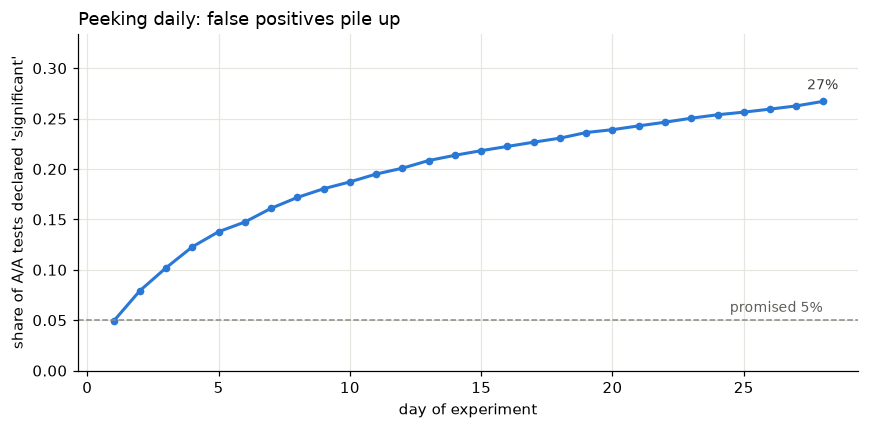

In [28]:
peek_rng = np.random.default_rng(6)
n_sims, n_days, n_per_day = 5_000, 28, 357

x_a = peek_rng.binomial(n_per_day, 0.05, (n_sims, n_days)).cumsum(axis=1)
x_b = peek_rng.binomial(n_per_day, 0.05, (n_sims, n_days)).cumsum(axis=1)
n_cum = n_per_day * np.arange(1, n_days + 1)
p_pool = (x_a + x_b) / (2 * n_cum)
se = np.sqrt(p_pool * (1 - p_pool) * (2 / n_cum))
z = (x_b - x_a) / n_cum / se
sig_daily = 2 * (1 - stats.norm.cdf(np.abs(z))) < ALPHA      # shape (sims, days)

ever_sig_by_day = np.maximum.accumulate(sig_daily, axis=1).mean(axis=0)
print(f"false positive rate, look once at day 28 : {sig_daily[:, -1].mean():.3f}")
print(f"false positive rate, peek every day      : {ever_sig_by_day[-1]:.3f}")

days = np.arange(1, n_days + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(days, ever_sig_by_day, color=C_BLUE, marker="o", markersize=4)
ax.axhline(ALPHA, color=C_GRAY, linestyle="--", linewidth=1)
ax.text(days[-1], ALPHA + 0.005, "promised 5%", color="#5f5e5a", fontsize=9, ha="right", va="bottom")
ax.annotate(f"{ever_sig_by_day[-1]:.0%}", (days[-1], ever_sig_by_day[-1]), xytext=(0, 8),
            textcoords="offset points", ha="center", color="#3d3d3a", fontsize=9)
ax.set_xlabel("day of experiment")
ax.set_ylabel("share of A/A tests declared 'significant'")
ax.set_ylim(0, max(ever_sig_by_day) * 1.25)
ax.set_title("Peeking daily: false positives pile up", loc="left")
plt.tight_layout()
plt.show()

### Problem 5 conclusion

**5a: SRM**

| Split | Result |
|---|---|
| Healthy splits (20k or 200k) | p = 0.50, 0.72 → no SRM. Random assignment is never exactly 50/50, and that's fine. |
| 3% of treatment lost, 20k users | p = 0.32 → **not detected** |
| 3% of treatment lost, 200k users | χ² = 55, p ≈ 0 → **SRM detected. Stop and debug, don't read the results.** |

**The catch:** SRM checks have power too. A 3% loss hides at 20k users and becomes obvious at 200k. Passing an SRM check on a small test doesn't prove the split is clean. And the lost users are usually *not* random (e.g. the users the new model crashed on), so the arms really are no longer comparable.

**5b: Peeking**
- Look once at day 28: false positive rate **4.8%** (as promised)
- Peek daily and stop at the first p < 0.05: **26.7%**, more than 5× the promise

Each daily look is another chance for random noise to cross the line, and once it crosses, you stop. Same idea as multiple testing (Problem 2), spread over time.

**The catch / fixes:**
1. Fix the sample size **in advance** (Problem 1) and decide only at the end.
2. If you must monitor (e.g. to stop a harmful change early), use a method built for it: **sequential testing** (alpha spending such as O'Brien-Fleming, or always-valid p-values / mSPRT). Many A/B platforms do this for you.
3. Looking at a dashboard is fine. **Stopping because of what you saw** is the problem.

# Cheat sheet: binary (0/1) A/B testing

| Situation | Test | Python |
|---|---|---|
| **Before** the test: how many users? | Power / sample size | `NormalIndPower().solve_power(proportion_effectsize(p_new, p_old), alpha=0.05, power=0.8)` |
| Two groups randomized at the same time | Two-proportion z-test (= chi-square on the 2×2 table) | `proportions_ztest([x_new, x_old], [n_new, n_old])`, `confint_proportions_2indep(...)` |
| Few conversions (< ~10 in a cell) | Fisher's exact test | `stats.fisher_exact([[x_new, n_new - x_new], [x_old, n_old - x_old]])` |
| One group vs a fixed known rate | One-sample z-test / exact binomial | `proportions_ztest(x, n, value=p0, prop_var=p0)`, `stats.binomtest(x, n, p0)` |
| Different periods + an untouched group | Difference-in-differences | by hand: SE = √(sum of the four variances) |
| Arm sizes vs planned split | SRM, chi-square goodness-of-fit | `stats.chisquare([n_a, n_b], f_exp=[...])` |

**Reading any result:**
- **SE**: precision. Shrinks with √n.
- **z = diff / SE**: how many wobbles from zero.
- **p-value**: how surprising the gap is *if nothing were going on*. Not the probability that H₀ is true.
- **CI**: what the true effect could be. Always report it next to the p-value.

**The traps, in one line each:**
1. Not significant ≠ no effect. Check the CI and the power.
2. Significant ≠ big enough to matter. Check the low end of the CI.
3. Low power → significant results overestimate the lift (winner's curse).
4. Non-concurrent comparisons (history, benchmarks) mix the model with time effects.
5. Many metrics or daily peeking → false positives far above 5%.
6. SRM fails → the whole test is invalid, whatever the p-value says.